# Clustering de documents

In [2]:
import os
os.environ["OPENBLAS_NUM_THREADS"] = "1"

## Imports

In [3]:
import collections
import os
import string
import sys

import pandas as pd
from nltk import word_tokenize
from nltk.corpus import stopwords
from pprint import pprint
from sklearn.cluster import KMeans
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import PCA
import numpy as np
import matplotlib.pyplot as plt
from scipy.spatial.distance import cosine

In [4]:
import nltk

nltk.download('punkt')
nltk.download("punkt_tab")

[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\Adam\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\Adam\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


True

In [5]:
data_path = "../../data/txt/"

## Choisir une décennie

In [6]:
DECADE = '1940'

## Charger tous les  fichiers de la décennie et en créer une liste de textes

In [7]:
files = [f for f in sorted(os.listdir(data_path)) if f"_{DECADE[:-1]}" in f]

In [8]:
# Exemple de fichiers
files[:5]

['KB_JB838_1940-01-04_01-00001.txt',
 'KB_JB838_1940-01-05_01-00009.txt',
 'KB_JB838_1940-01-07_01-00014.txt',
 'KB_JB838_1940-01-10_01-00003.txt',
 'KB_JB838_1940-01-11_01-00004.txt']

In [9]:
texts = [open(data_path + f, "r", encoding="utf-8").read() for f in files]

In [10]:
# Exemple de textes
texts[0][:400]

"54 e ANNEE. — N° 4. Pages - 40 C 1 *® 8 Grand-Duché : 45 centimes. - France : 75 centime». ABONNEMENTS pour la province on Province } s'abonne à là Poste CH' Vüle au $ pour | T , oi , ŒOl# 28>50 BUREAUX ET FILS SPÉCIAUX: — — ■ ; S Un an 170.00 Congo • j Six mol , 85X0 Etranger : Prix euivant conventions VENTE ET ABONNEM. : PLACE DE LOUVAIN. 23 □ SALLE DE DÉPÊCHES : 124. RUE ROYALE BRUXELLES G “ ■“"

## Vectoriser les documents à l'aide de TF-IDF

In [11]:
# Création d'une fonction de pré-traitement
def preprocessing(text, stem=True):
    """ Tokenize text and remove punctuation """
    text = text.translate(string.punctuation)
    tokens = word_tokenize(text)
    return tokens

### Instancier le modèle TF-IDF avec ses arguments

In [12]:
vectorizer = TfidfVectorizer(
    tokenizer=preprocessing,
    stop_words=stopwords.words('french'),
    max_df=0.5,
    min_df=0.1,
    lowercase=True)

### Construire la matrice de vecteurs à l'aide de la fonction `fit_transform`

In [13]:
tfidf_vectors = vectorizer.fit_transform(texts)

c:\Projets\tac\.venv\Lib\site-packages\sklearn\feature_extraction\text.py:527: UserWarning: The parameter 'token_pattern' will not be used since 'tokenizer' is not None'
  warnings.warn(


In [14]:
# Détail de la matrice
tfidf_vectors

<Compressed Sparse Row sparse matrix of dtype 'float64'
	with 938802 stored elements and shape (1000, 4628)>

### Imprimer le vecteur tf-IDF du premier document

In [15]:
pd.Series(
    tfidf_vectors[0].toarray()[0],
    index=vectorizer.get_feature_names_out()
    ).sort_values(ascending=False)

gouvernement    0.158146
milieux         0.154213
cabinet         0.132669
quelle          0.120831
neige           0.117768
                  ...   
-a              0.000000
-1              0.000000
+               0.000000
ê               0.000000
état-major      0.000000
Length: 4628, dtype: float64

## Comprendre les vecteurs et leurs "distances"

In [16]:
cosine([1, 2, 3], [1, 2, 3])

np.float64(0.0)

In [17]:
cosine([1, 2, 3], [1, 2, 2])

np.float64(0.02004211298777725)

In [18]:
cosine([1, 2, 3], [2, 2, 2])

np.float64(0.07417990022744858)

### Tests sur nos documents

In [19]:
tfidf_array = tfidf_vectors.toarray()

In [20]:
# Vecteur du document 0
tfidf_array[0]

array([0., 0., 0., ..., 0., 0., 0.], shape=(4628,))

In [21]:
# Vecteur du document 1
tfidf_array[1]

array([0.00714122, 0.        , 0.        , ..., 0.00656754, 0.        ,
       0.        ], shape=(4628,))

In [22]:
cosine(tfidf_array[0], tfidf_array[1])

np.float64(0.9558126378958469)

## Appliquer un algorithme de clustering sur les vecteurs TF-IDF des documents

Pour en savoir plus sur le KMeans clustering :
- https://medium.com/dataseries/k-means-clustering-explained-visually-in-5-minutes-b900cc69d175

### Définir un nombre de clusters

In [23]:
N_CLUSTERS = 5

### Instancier le modèle K-Means et ses arguments

In [24]:
km_model = KMeans(n_clusters=N_CLUSTERS, random_state=42)

### Appliquer le clustering à l'aide de la fonction `fit_predict`

In [25]:
clusters = km_model.fit_predict(tfidf_vectors)

In [26]:
clustering = collections.defaultdict(list)

for idx, label in enumerate(clusters):
    clustering[label].append(files[idx])

In [27]:
pprint(dict(clustering))

{np.int32(0): ['KB_JB838_1940-01-19_01-00005.txt',
               'KB_JB838_1940-02-01_01-00006.txt',
               'KB_JB838_1940-02-06_01-00005.txt',
               'KB_JB838_1940-02-07_01-00005.txt',
               'KB_JB838_1940-02-09_01-00005.txt',
               'KB_JB838_1940-02-12_01-00005.txt',
               'KB_JB838_1940-02-18_01-00014.txt',
               'KB_JB838_1940-02-20_01-00007.txt',
               'KB_JB838_1940-02-29_01-00005.txt',
               'KB_JB838_1940-03-02_01-00007.txt',
               'KB_JB838_1940-03-04_01-00005.txt',
               'KB_JB838_1940-03-10_01-00008.txt',
               'KB_JB838_1940-04-03_01-00007.txt',
               'KB_JB838_1940-04-22_01-00005.txt',
               'KB_JB838_1940-06-19_01-00002.txt',
               'KB_JB838_1940-06-30_01-00005.txt',
               'KB_JB838_1940-07-21_01-00005.txt',
               'KB_JB838_1940-07-22_01-00006.txt',
               'KB_JB838_1940-07-24_01-00005.txt',
               'KB_JB838_1940-0

## Visualiser les clusters

### Réduire les vecteurs à 2 dimensions à l'aide de l'algorithme PCA
Cette étape est nécessaire afin de visualiser les documents dans un espace 2D

https://fr.wikipedia.org/wiki/Analyse_en_composantes_principales

In [28]:
pca = PCA(n_components=2)
reduced_vectors = pca.fit_transform(tfidf_vectors.toarray())

In [29]:
reduced_vectors[:10]

array([[-0.26062573,  0.16961688],
       [ 0.61399377,  0.18142991],
       [ 0.12166161, -0.07515432],
       [-0.29795121,  0.28243567],
       [-0.26356978,  0.13307567],
       [-0.19489241, -0.15517973],
       [-0.28232396,  0.1945773 ],
       [-0.24984898,  0.14138341],
       [-0.11653937, -0.14630321],
       [ 0.45296945,  0.04193361]])

### Générer le plot

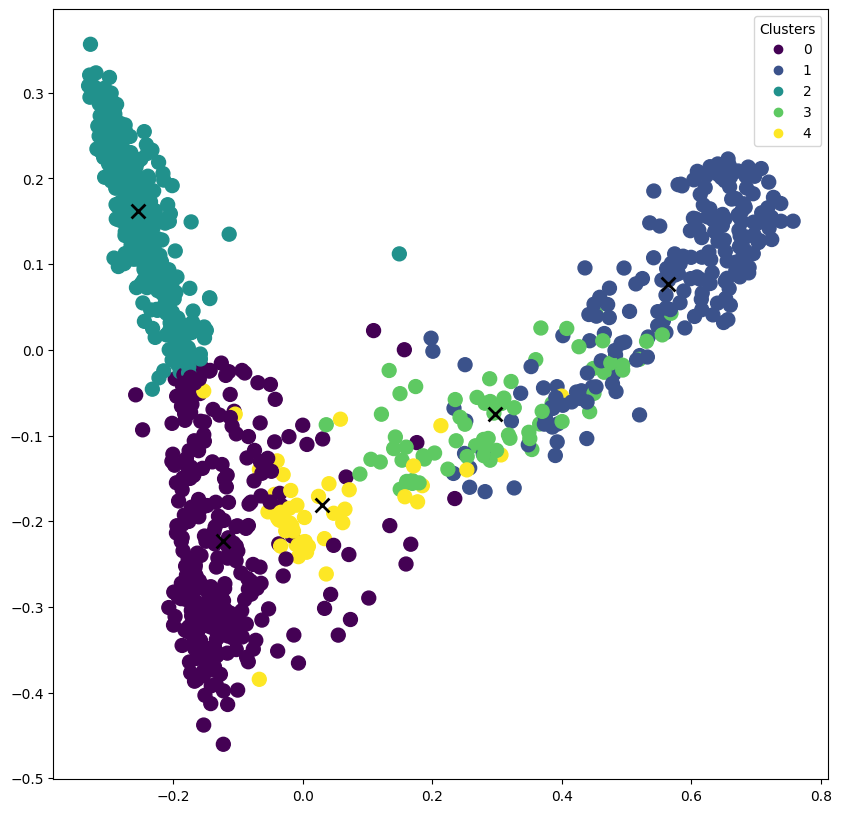

In [30]:
x_axis = reduced_vectors[:, 0]
y_axis = reduced_vectors[:, 1]

plt.figure(figsize=(10,10))
scatter = plt.scatter(x_axis, y_axis, s=100, c=clusters)

# Ajouter les centroïdes
centroids = pca.transform(km_model.cluster_centers_)
plt.scatter(centroids[:, 0], centroids[:, 1],  marker = "x", s=100, linewidths = 2, color='black')

# Ajouter la légende
plt.legend(handles=scatter.legend_elements()[0], labels=set(clusters), title="Clusters")
plt.savefig("clusters_pca.png", dpi=150, bbox_inches="tight")

In [31]:
print(DECADE, len(files), files[0], files[-1])

1940 1000 KB_JB838_1940-01-04_01-00001.txt KB_JB838_1949-12-28_01-00010.txt


In [32]:
print(sorted(collections.Counter(clusters).items()))

[(np.int32(0), 290), (np.int32(1), 200), (np.int32(2), 391), (np.int32(3), 69), (np.int32(4), 50)]


In [33]:
terms = vectorizer.get_feature_names_out()
order = km_model.cluster_centers_.argsort()[:, ::-1]
for c in range(N_CLUSTERS):
    print(f"Cluster {c} :", ", ".join(terms[i] for i in order[c, :12]))

Cluster 0 : p.s, cap, match, course, bat, admis, division, équipe, points, championnat, mutuel, mètres
Cluster 1 : dem, rossel, ag, ecr, ecrire, ec, louer, ec.ag.rossel, app, n®, cherche, ag.rossel
Cluster 2 : gouvernement, ministre, politique, troupes, allemands, allemagne, etats-unis, britannique, forces, berlin, front, allemande
Cluster 3 : vend, ag, rossel, vendre, hp, ford, cv, z, ecr, ecrire, chevrolet, pneus
Cluster 4 : notaire, ca, etude, faç, visites, cont, jardin, lot, rentier, ares, m2, commune


In [34]:
def page(f): return int(f.split("_")[-1][:-4].split("-")[1])
for c in range(N_CLUSTERS):
    pages = collections.Counter(page(files[i]) for i, l in enumerate(clusters) if l == c)
    print(c, sorted(pages.items()))

0 [(1, 2), (2, 74), (3, 45), (4, 28), (5, 38), (6, 48), (7, 19), (8, 24), (9, 1), (11, 1), (12, 4), (14, 2), (16, 1), (18, 1), (20, 2)]
1 [(2, 22), (3, 19), (4, 37), (5, 18), (6, 7), (7, 12), (8, 16), (9, 18), (10, 25), (11, 5), (12, 10), (13, 5), (14, 2), (15, 3), (18, 1)]
2 [(1, 191), (2, 87), (3, 53), (4, 21), (5, 20), (6, 9), (7, 4), (8, 1), (9, 3), (10, 1), (11, 1)]
3 [(4, 1), (7, 8), (8, 3), (9, 4), (10, 6), (11, 9), (12, 14), (13, 6), (14, 7), (15, 1), (16, 7), (17, 1), (18, 2)]
4 [(2, 8), (3, 3), (4, 11), (5, 4), (6, 2), (7, 4), (8, 7), (9, 2), (10, 5), (11, 3), (12, 1)]


In [35]:
# Lire 3 documents par cluster, pour vérifier les étiquettes
for c in range(N_CLUSTERS):
    idx = [i for i, l in enumerate(clusters) if l == c][:3]
    for i in idx:
        print(c, files[i], texts[i][:300].replace("\n", " "))
        print()

0 KB_JB838_1940-01-19_01-00005.txt 5—519 JANVIER** * * S LES CONSEILS DE LO-TRI-KO Pour avoir nue bonne pêche il faut d'abord amorcer n ligne La meilleure amorce pour pêcher une fortune ne coûte que quelques francs. C’est un billet de la 992-1 LOTERIE COLONIALE Tirage de la Ire tranche 1940 SAMEDI 27 JANVIER FAITS-DIVERS — DEUX AUTOC

0 KB_JB838_1940-02-01_01-00006.txt 6 <coianjiaQua&) X I. O. (parte le Wanrar) : la MliH (K«my Baker-Jeu Colin). Ven. orgin., e/tltres. E.ad. £IOU> (S7.Chaxtrtaz) :1m Bekfme. Joyeme mt. ARENBERG : T*a)»ar» Martre (Gracie Fiel de). AVENUE : c H > le MaMBt (Peter Lorre). ■ BEAIIX-AITS: Et la renie fat... ( Fonda-Young). GâlUtO: Aa/vmlr,

0 KB_JB838_1940-02-06_01-00005.txt ÊÊÊSSSS6 FÉVRIER MjaÊÊÊaÊÊÊmmm^mmÊlàmÊÊimim^imÊÊSÊÊSmmÊMSÊÊÿmÈmmm¥mmÊÊÈiÊÊm ' LE SOIR |u Piwrfèrtt a farts ‘.THEATRE DES AMBASSADEURS ELVIRE quatre actes de M. Henry Bernstein Jean Viroy est un grand avocat. Il est aussi un grancl amoureux. La pièce nouvelle de Bernstein se propose de nous 

In [36]:
# Tester d'autres nombres de clusters
for k in (3, 8):
    km = KMeans(n_clusters=k, random_state=42).fit(tfidf_vectors)
    order = km.cluster_centers_.argsort()[:, ::-1]
    print("k =", k)
    for c in range(k):
        print(c, (km.labels_ == c).sum(), ", ".join(terms[i] for i in order[c, :8]))

k = 3
0 347 p.s, cap, match, course, notaire, bat, admis, division
1 269 dem, rossel, ag, ecr, ecrire, ec, vend, vendre
2 384 gouvernement, ministre, politique, troupes, allemands, allemagne, britannique, etats-unis
k = 8
0 158 ot, musique, concert, monsieur, théâtre, novembre, œuvre, juin
1 216 dem, rossel, ag, ecr, ecrire, ec, louer, ec.ag.rossel
2 295 gouvernement, ministre, politique, troupes, allemands, allemagne, britannique, etats-unis
3 56 vend, ford, hp, cv, vendre, z, ag, chevrolet
4 107 match, bat, course, division, équipe, mètres, pts, mutuel
5 39 notaire, ca, etude, faç, visites, lot, cont, rentier
6 64 admis, p.s, enf, mod, e.a, pari, cap, course
7 65 p.s, cap, katanga, valeurs, oo, réduit, emprunts, ord


In [37]:
# Extrait du milieu de la page, pour 3 documents du cluster 3
idx = [i for i, l in enumerate(clusters) if l == 3][:3]
for i in idx:
    m = len(texts[i]) // 2
    print(files[i], texts[i][m:m+400].replace("\n", " "))
    print()

KB_JB838_1940-01-07_01-00014.txt ssante, les manches froncées sont gracieuses, le petit col peut se porter ouvert ou fermé, et les poches sont pratiques. C’est un excellent patron pour lequel vous pourrez utiliser un coton peu coûteux ou une belle soie. Nous pouvons fournir à nos lectrices le patron de l’ensemble au prix de 4 fr. en taille 44. Les autres tailles au prix de 7 francs. Paiement au C. C. P. « Soir Illustré» n° 5675 o

KB_JB838_1940-02-05_01-00008.txt bMtahstlan comprise), MAISON HABITATION èt MAISON DERRIERE. Ineutlnn 28.000 ; fr. Intermédiaires' s'abstenir. Téléphonez > au numéro 12.83 92.: 49023 N ImachinÊs-outilsT Matériell k ■ «mmm ■ ■■■■■ ■ mtmmm «J A VEND. 1200, moteurs élect. Qoinet, 673,ch. de Mons.T.21.43-38 29270 R CH. 1°) maeb. A lessiver av. foy. : 2" ) mant. enlr.Ecr. Ag.Rossel 13983 A VENDRE Plusieurs, moteurs stationnaires (fab.

KB_JB838_1940-04-17_01-00012.txt ; prix nwd, -163, rue Gof- fiprt.T;48.76.70 - 49716+ Déménagements — Garde-Meubles G. GRANVILLE 1